# Product Review Sentiment Classifier

This notebook builds a sentiment classifier for real customer reviews and compares:

1. A classical machine-learning baseline: **TF-IDF + Logistic Regression**
2. A pretrained transformer model: **`cardiffnlp/twitter-roberta-base-sentiment-latest`**

Both models are evaluated on the **exact same train/test split**. The evaluation focuses on per-class precision, recall and F1-score rather than accuracy alone, because sentiment datasets can be imbalanced and individual classes may behave differently.

**Sentiment labels:**

- 1–2 star reviews → `negative`
- 3 star reviews → `neutral`
- 4–5 star reviews → `positive`


In [1]:
!pip install -q scikit-learn pandas numpy matplotlib datasets transformers torch

In [2]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight
from transformers import pipeline

SEED = 42
LABELS = ["negative", "neutral", "positive"]

random.seed(SEED)
np.random.seed(SEED)

print("Libraries loaded successfully.")

Libraries loaded successfully.


## Dataset

This project uses the **Yelp Review Full** dataset, which contains real customer reviews with star ratings from 1 to 5.

The dataset is publicly available through Hugging Face Datasets. For efficient execution in Colab, a balanced sample is taken from the full dataset.

The original star ratings are converted into three sentiment classes:

| Star rating | Sentiment |
|---|---|
| 1–2 | Negative |
| 3 | Neutral |
| 4–5 | Positive |

In [3]:
dataset = load_dataset("Yelp/yelp_review_full")

train_raw = dataset["train"].to_pandas()
test_raw = dataset["test"].to_pandas()

train_raw = train_raw.rename(columns={"text": "review", "label": "star_label"})
test_raw = test_raw.rename(columns={"text": "review", "label": "star_label"})

print("Original train size:", train_raw.shape)
print("Original test size:", test_raw.shape)

train_raw.head()

README.md:   0%|          | 0.00/6.72k [00:00<?, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  299MB            

yelp_review_full/train-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

yelp_review_full/test-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 23.5MB            

yelp_review_full/test-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Original train size: (650000, 2)
Original test size: (50000, 2)


,star_label,review
0,4,dr. goldberg offers everything i look for in a...
1,1,"Unfortunately, the frustration of being Dr. Go..."
2,3,Been going to Dr. Goldberg for over 10 years. ...
3,3,Got a letter in the mail last week that said D...
4,0,I don't know what Dr. Goldberg was like before...


In [4]:
def star_to_sentiment(label):
    if label in [0, 1]:
        return "negative"
    elif label == 2:
        return "neutral"
    else:
        return "positive"

train_raw["sentiment"] = train_raw["star_label"].apply(star_to_sentiment)
test_raw["sentiment"] = test_raw["star_label"].apply(star_to_sentiment)

train_df_raw = train_raw[["review", "sentiment"]]
test_df_raw = test_raw[["review", "sentiment"]]

print(train_df_raw["sentiment"].value_counts())
print()
print(test_df_raw["sentiment"].value_counts())

sentiment
positive    260000
negative    260000
neutral     130000
Name: count, dtype: int64

sentiment
negative    20000
positive    20000
neutral     10000
Name: count, dtype: int64


## Class Distribution and Sampling

The full Yelp dataset is very large, so a balanced subset is created for practical training and evaluation in Colab.

The sampling is stratified: each sentiment class contains the same number of examples. This prevents the models from being biased toward the majority class and makes the comparison between the two models fair.

The final dataset contains:

- 9,000 training examples
- 3,000 test examples
- 3,000 examples per sentiment class in the training set
- 1,000 examples per sentiment class in the test set

In [5]:
TRAIN_PER_CLASS = 3000
TEST_PER_CLASS = 1000

def balanced_sample(df, per_class):
    sampled_parts = []

    for sentiment in LABELS:
        part = df[df["sentiment"] == sentiment]
        sampled_parts.append(part.sample(n=per_class, random_state=SEED))

    sampled = pd.concat(sampled_parts, ignore_index=True)
    return sampled.sample(frac=1, random_state=SEED).reset_index(drop=True)

train_df = balanced_sample(train_df_raw, TRAIN_PER_CLASS)
test_df = balanced_sample(test_df_raw, TEST_PER_CLASS)

print("Train class distribution:")
print(train_df["sentiment"].value_counts())

print("\nTest class distribution:")
print(test_df["sentiment"].value_counts())

Train class distribution:
sentiment
positive    3000
negative    3000
neutral     3000
Name: count, dtype: int64

Test class distribution:
sentiment
neutral     1000
negative    1000
positive    1000
Name: count, dtype: int64


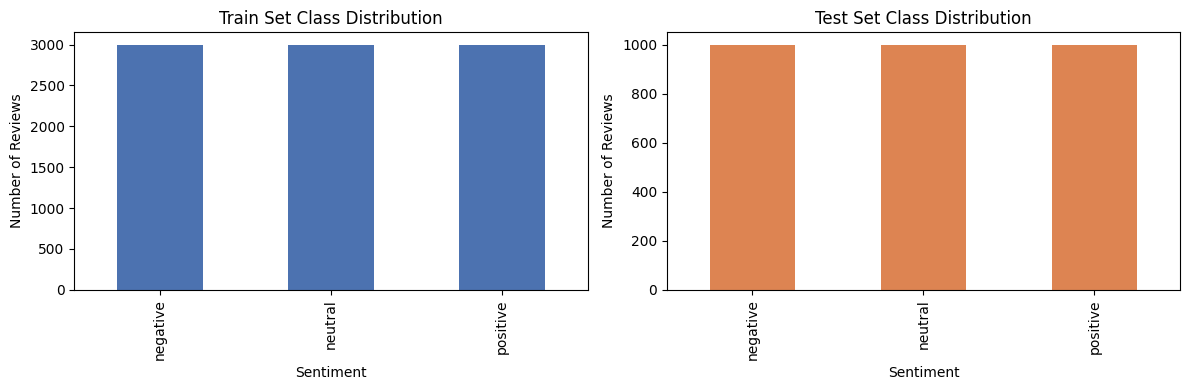

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_df["sentiment"].value_counts().reindex(LABELS).plot(
    kind="bar", ax=axes[0], color="#4C72B0"
)
axes[0].set_title("Train Set Class Distribution")
axes[0].set_xlabel("Sentiment")
axes[0].set_ylabel("Number of Reviews")

test_df["sentiment"].value_counts().reindex(LABELS).plot(
    kind="bar", ax=axes[1], color="#DD8452"
)
axes[1].set_title("Test Set Class Distribution")
axes[1].set_xlabel("Sentiment")
axes[1].set_ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

## Identical Train/Test Split

To ensure a valid comparison, both models use the same `train_df` and `test_df` DataFrames.

The split files are also saved locally. This means the classical model and the transformer model are evaluated on exactly the same examples, with the same random seed used throughout the notebook.

In [7]:
os.makedirs("data", exist_ok=True)

train_df.to_csv("data/train_split.csv", index=False)
test_df.to_csv("data/test_split.csv", index=False)

print("Train and test splits saved successfully.")
print("Train size:", len(train_df))
print("Test size:", len(test_df))

Train and test splits saved successfully.
Train size: 9000
Test size: 3000


## Classical Baseline: TF-IDF + Logistic Regression

The classical baseline uses:

- `TfidfVectorizer` to convert review text into numerical features
- Unigrams and bigrams to capture simple word combinations
- Logistic Regression as the classifier

Class imbalance is handled using `class_weight="balanced"`. This gives more weight to underrepresented classes during training.

In this balanced sample the classes are already equal, but the weighting is still applied deliberately because the original dataset is imbalanced and the approach would remain valid if the sampling strategy changed.

In [8]:
tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=20000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.9
)

X_train_tfidf = tfidf.fit_transform(train_df["review"])
X_test_tfidf = tfidf.transform(test_df["review"])

y_train = train_df["sentiment"]
y_test = test_df["sentiment"]

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

print("Classes:", classes)
print("Class weights:")
print(dict(zip(classes, class_weights)))

Classes: ['negative' 'neutral' 'positive']
Class weights:
{'negative': np.float64(1.0), 'neutral': np.float64(1.0), 'positive': np.float64(1.0)}


In [9]:
logreg = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)

logreg.fit(X_train_tfidf, y_train)

logreg_preds = logreg.predict(X_test_tfidf)

print("TF-IDF + Logistic Regression Classification Report")
print(classification_report(y_test, logreg_preds, labels=LABELS, digits=4))

TF-IDF + Logistic Regression Classification Report
              precision    recall  f1-score   support

    negative     0.7377    0.7510    0.7443      1000
     neutral     0.5792    0.5780    0.5786      1000
    positive     0.7337    0.7220    0.7278      1000

    accuracy                         0.6837      3000
   macro avg     0.6835    0.6837    0.6836      3000
weighted avg     0.6835    0.6837    0.6836      3000



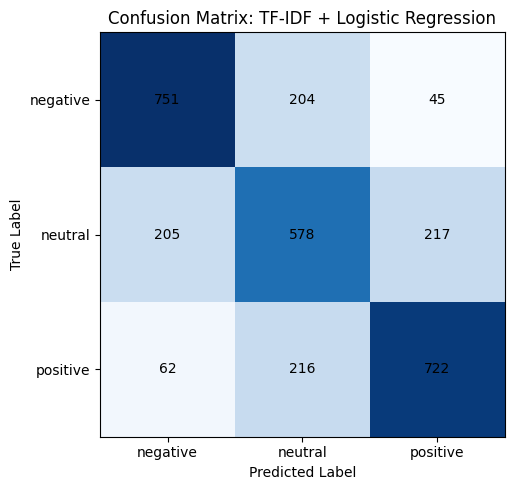

In [10]:
cm_logreg = confusion_matrix(y_test, logreg_preds, labels=LABELS)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_logreg, cmap="Blues")

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(LABELS)
ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Confusion Matrix: TF-IDF + Logistic Regression")

for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(
            j, i, cm_logreg[i, j],
            ha="center", va="center", color="black"
        )

plt.tight_layout()
plt.show()

## Transformer Model

For the transformer approach, the pretrained model **`cardiffnlp/twitter-roberta-base-sentiment-latest`** is used.

This model was trained for three-class sentiment classification and outputs one of the following labels:

- `negative`
- `neutral`
- `positive`

**Important note:** This notebook uses a pretrained transformer directly. The model is **not fine-tuned** on the Yelp dataset. This is stated explicitly because the task allows either a well-matched pretrained model or a fine-tuned transformer.

The transformer is applied to the same test set used for the classical baseline.

In [11]:
MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"

sentiment_pipeline = pipeline(
    "sentiment-analysis",
    model=MODEL_NAME,
    tokenizer=MODEL_NAME,
    device=0
)

print("Transformer model loaded:", MODEL_NAME)

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Transformer model loaded: cardiffnlp/twitter-roberta-base-sentiment-latest


In [12]:
def truncate_text(text, max_chars=512):
    text = str(text).strip()
    return text[:max_chars]

test_reviews = test_df["review"].apply(truncate_text).tolist()

transformer_results = sentiment_pipeline(
    test_reviews,
    batch_size=32,
    truncation=True
)

transformer_preds = [result["label"].lower() for result in transformer_results]
transformer_confidences = [result["score"] for result in transformer_results]

test_df["transformer_prediction"] = transformer_preds
test_df["transformer_confidence"] = transformer_confidences

print("Pretrained Transformer Classification Report")
print(classification_report(y_test, transformer_preds, labels=LABELS, digits=4))

Pretrained Transformer Classification Report
              precision    recall  f1-score   support

    negative     0.7228    0.7120    0.7174      1000
     neutral     0.4295    0.1310    0.2008      1000
    positive     0.5275    0.9020    0.6657      1000

    accuracy                         0.5817      3000
   macro avg     0.5599    0.5817    0.5279      3000
weighted avg     0.5599    0.5817    0.5279      3000



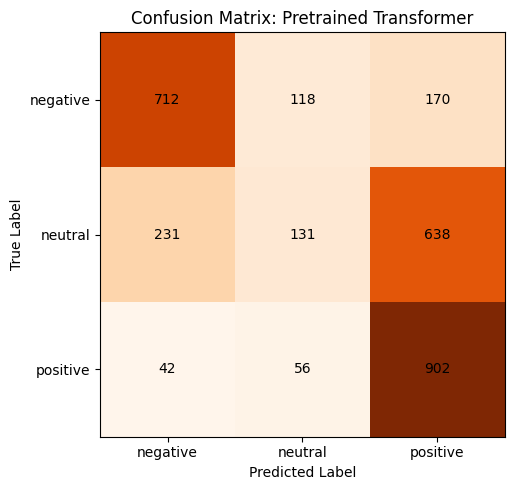

In [13]:
cm_transformer = confusion_matrix(y_test, transformer_preds, labels=LABELS)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_transformer, cmap="Oranges")

ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(LABELS)
ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title("Confusion Matrix: Pretrained Transformer")

for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(
            j, i, cm_transformer[i, j],
            ha="center", va="center", color="black"
        )

plt.tight_layout()
plt.show()

## Model Comparison

The models are compared using:

- **Accuracy:** overall proportion of correct predictions
- **Macro F1:** unweighted average of F1-scores across classes
- **Weighted F1:** F1-score weighted by class support

Macro F1 is especially important here because it treats each sentiment class equally. A model can achieve high accuracy while performing poorly on the neutral class, so accuracy alone is not enough.

In [14]:
comparison_df = pd.DataFrame({
    "Model": [
        "TF-IDF + Logistic Regression",
        "Pretrained Transformer"
    ],
    "Accuracy": [
        accuracy_score(y_test, logreg_preds),
        accuracy_score(y_test, transformer_preds)
    ],
    "Macro F1": [
        f1_score(y_test, logreg_preds, average="macro", labels=LABELS),
        f1_score(y_test, transformer_preds, average="macro", labels=LABELS)
    ],
    "Weighted F1": [
        f1_score(y_test, logreg_preds, average="weighted", labels=LABELS),
        f1_score(y_test, transformer_preds, average="weighted", labels=LABELS)
    ]
})

comparison_df

,Model,Accuracy,Macro F1,Weighted F1
0,TF-IDF + Logistic Regression,0.683667,0.683567,0.683567
1,Pretrained Transformer,0.581667,0.527943,0.527943


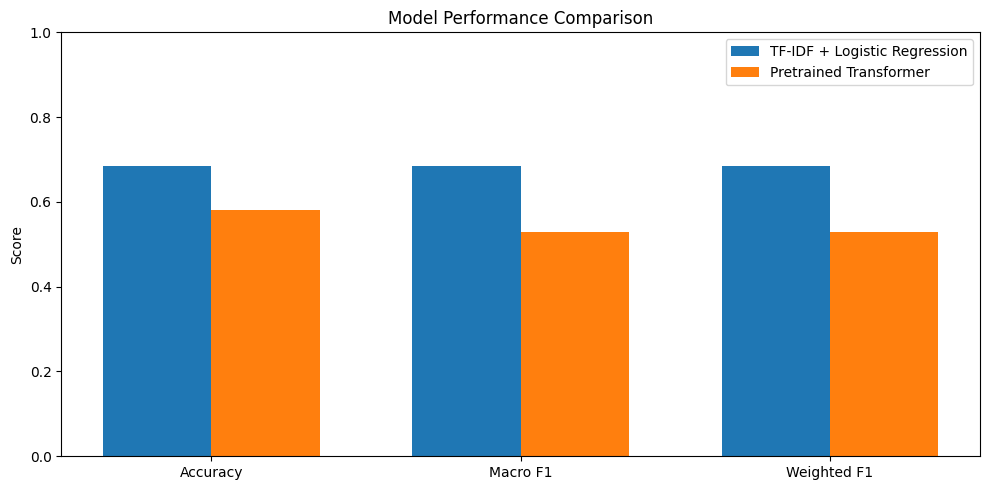

In [15]:
metrics = ["Accuracy", "Macro F1", "Weighted F1"]

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(metrics))
width = 0.35

ax.bar(
    x - width / 2,
    comparison_df.iloc[0][metrics].astype(float),
    width,
    label=comparison_df.iloc[0]["Model"]
)

ax.bar(
    x + width / 2,
    comparison_df.iloc[1][metrics].astype(float),
    width,
    label=comparison_df.iloc[1]["Model"]
)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Model Performance Comparison")
ax.legend()

plt.tight_layout()
plt.show()

## Error Analysis

Misclassified examples are inspected to identify possible systematic weaknesses.

The main goal is not simply to count errors, but to understand why they occur. Common reasons for sentiment classification errors include mixed sentiment, negation, sarcasm, long reviews and ambiguous neutral reviews.

In [16]:
test_df["classical_prediction"] = logreg_preds
test_df["true_sentiment"] = y_test.values

classical_errors = test_df[
    test_df["classical_prediction"] != test_df["true_sentiment"]
].copy()

transformer_errors = test_df[
    test_df["transformer_prediction"] != test_df["true_sentiment"]
].copy()

print("Classical model errors:", len(classical_errors))
print("Transformer model errors:", len(transformer_errors))

Classical model errors: 949
Transformer model errors: 1255


In [17]:
def show_errors(error_df, prediction_column, model_name, n=5):
    print(f"\n===== {model_name}: Misclassified Examples =====\n")

    samples = error_df.sample(n=min(n, len(error_df)), random_state=SEED)

    for _, row in samples.iterrows():
        print("Review:")
        print(row["review"][:500])
        print()
        print("True sentiment:", row["true_sentiment"])
        print("Predicted sentiment:", row[prediction_column])
        print("-" * 80)

show_errors(
    classical_errors,
    "classical_prediction",
    "TF-IDF + Logistic Regression"
)

show_errors(
    transformer_errors,
    "transformer_prediction",
    "Pretrained Transformer"
)


===== TF-IDF + Logistic Regression: Misclassified Examples =====

Review:
Went in not expecting too much, and if you do that, it's not bad, although still pricey.\n\nWe stopped in because we were late to watch one of the world cup games and needed to grab a quick breakfast. I got the two eggs breakfast and my wife got just two eggs. \n\nThe food was decent: eggs were done ok, sausage was fine, toast was good. The hash browns, however, arrived in a sort of \"brick\" and were greasy and rather tasteless.  I presume they came frozen in that shape and had just been tossed

True sentiment: negative
Predicted sentiment: neutral
--------------------------------------------------------------------------------
Review:
I LOVE the food here, you can make your own stuff, combination, veggies and stuff.  delicious! the FOOD is great,\n\nThe service however, could be better, faster and more attentive.\n\nRonney

True sentiment: neutral
Predicted sentiment: positive
---------------------------------

### Error Hypotheses

Based on the misclassified examples, the following patterns are likely:

1. **Mixed sentiment:** Some reviews contain both positive and negative opinions. For example, a customer may like the product itself but complain about delivery, packaging or price.

2. **Ambiguous neutral reviews:** Three-star reviews are not always clearly neutral. A reviewer may be partially satisfied but still mention several problems.

3. **Negation:** Phrases such as “not bad”, “not worth the price” or “did not work as expected” can be difficult for a TF-IDF-based model because it focuses on individual words and n-grams rather than full sentence meaning.

4. **Sarcasm and irony:** A review such as “Great, another broken product” uses positive words in a negative context. This can mislead both classical and transformer-based models.

5. **Long reviews with several topics:** A long review may discuss product quality, shipping, customer service and price at the same time. The model must assign one overall sentiment to a review that contains several opinions.

6. **Domain mismatch for the transformer:** The pretrained transformer was not trained specifically on Yelp reviews. Although it generalizes well, some review-specific language and rating patterns may still be misunderstood.

## Confidence Calibration Check

This section checks whether higher transformer confidence scores correspond to more accurate predictions.

If the model is well calibrated, prediction accuracy should generally increase as confidence increases.

In [18]:
test_df["transformer_correct"] = (
    test_df["transformer_prediction"] == test_df["true_sentiment"]
).astype(int)

bins = [0.0, 0.5, 0.7, 0.85, 1.0]
bin_labels = ["0.00-0.50", "0.50-0.70", "0.70-0.85", "0.85-1.00"]

test_df["confidence_bin"] = pd.cut(
    test_df["transformer_confidence"],
    bins=bins,
    labels=bin_labels,
    include_lowest=True
)

calibration_df = (
    test_df.groupby("confidence_bin", observed=True)["transformer_correct"]
    .agg(["mean", "count"])
    .reset_index()
    .rename(columns={
        "mean": "accuracy",
        "count": "number_of_examples"
    })
)

calibration_df

,confidence_bin,accuracy,number_of_examples
0,0.00-0.50,0.408730,252
1,0.50-0.70,0.391137,519
2,0.70-0.85,0.494058,589
3,0.85-1.00,0.700000,1640


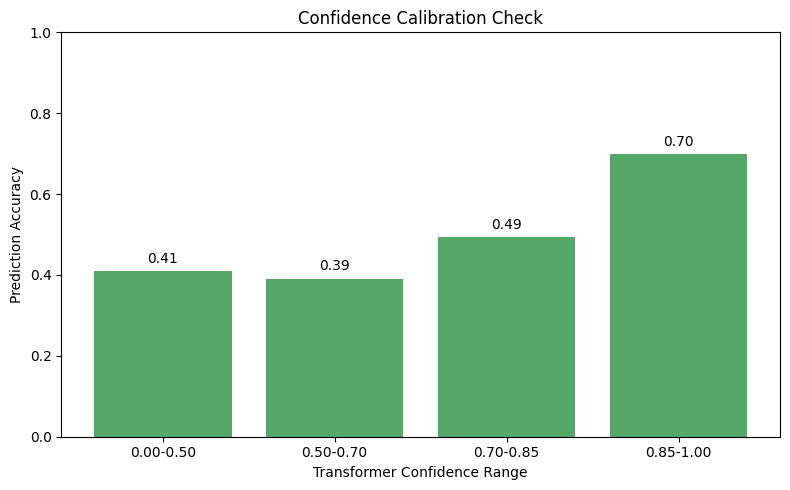

In [19]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    calibration_df["confidence_bin"].astype(str),
    calibration_df["accuracy"],
    color="#55A868"
)

ax.set_ylim(0, 1)
ax.set_xlabel("Transformer Confidence Range")
ax.set_ylabel("Prediction Accuracy")
ax.set_title("Confidence Calibration Check")

for index, value in enumerate(calibration_df["accuracy"]):
    ax.text(index, value + 0.02, f"{value:.2f}", ha="center")

plt.tight_layout()
plt.show()

## Model Comparison Verdict

The better model to deploy depends on the intended use case.

### Real-time customer support triage

For a real-time system that automatically routes customer reviews or support messages, **TF-IDF + Logistic Regression** is often the more practical choice.

It is lightweight, fast and easy to deploy. It requires significantly fewer computational resources than a transformer and can run comfortably on a CPU. If its per-class F1-score is close to the transformer’s performance, the simplicity and low latency make it a strong deployment candidate.

### Offline weekly reporting

For offline analysis, such as a weekly product-quality report, the **pretrained transformer** is likely the better option.

Latency is less important in this scenario, while stronger contextual understanding can improve the quality of sentiment insights. The transformer is especially useful when reviews contain longer context, negation or mixed opinions.

### Final recommendation

The final deployment decision should be based on:

- Per-class F1-score, especially for the neutral class
- Available inference latency budget
- CPU versus GPU availability
- Cost of hosting the model
- Importance of contextual understanding

If the transformer provides a clear improvement in macro F1 and the application can tolerate higher latency, deploy the transformer. If both models perform similarly and the system needs fast, low-cost predictions, deploy the TF-IDF + Logistic Regression baseline.

## Bonus: Live Testing Function

The following function allows a new review to be tested directly using the pretrained transformer model.

In [20]:
def predict_sentiment(review_text):
    result = sentiment_pipeline(truncate_text(review_text))[0]

    return {
        "review": review_text,
        "predicted_sentiment": result["label"].lower(),
        "confidence": round(result["score"], 4)
    }

predict_sentiment(
    "The product works fine, but the delivery was late and the packaging was damaged."
)

{'review': 'The product works fine, but the delivery was late and the packaging was damaged.',
 'predicted_sentiment': 'negative',
 'confidence': 0.7014}

## Conclusion

This notebook satisfies the main requirements of the task:

- Uses a real-world review dataset with more than 1,000 labeled examples
- Builds a classical TF-IDF + Logistic Regression baseline
- Uses a pretrained transformer for the same classification task
- Evaluates both models on the identical train/test split
- Reports precision, recall and F1-score for each sentiment class
- Measures class distribution and applies class weighting
- Reviews misclassified examples and provides error hypotheses
- Provides a deployment recommendation based on the accuracy-latency-resource trade-off

Bonus components included:

- A neutral sentiment class
- A confidence calibration check
- A simple live-testing function for new reviews